**Lab 1: Phishing URL Detection — EDA,** **Parameterized Logistic Regression & SHAP Explainability**

---

## 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027

🧭 Lab Overview & Solution Key

This notebook contains the assignment of **Lab 1** on the **[PhiUSIIL Phishing URL Dataset](https://www.kaggle.com/datasets/kaggleprollc/phishing-url-websites-dataset-phiusiil/data)** (*235,795 URLs and 56 lexical, network, and HTML features*, Prasad & Chandra, *Computers & Security*, 2024).

### 📋 Table of Contents
* **1 - Importing Packages & Loading Data**
* **2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)**
  * 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)
  * 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)
  * 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)
  * *Part 1 Reflection Questions*
* **3 - Part 2: Zero-Data Leakage Preprocessing & Standardization**
  * 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)
  * *Part 2 Reflection Questions*
* **4 - Part 3: Parameterized Logistic Regression & Interpretability**
  * 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)
  * 4.2 L1 Regularization Path & Feature Selection (Exercise 6)
  * 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)
  * *Part 3 Reflection Questions*
* **5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis**
  * 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)
  * 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)
  * 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)
  * *Part 4 Reflection Questions*
* **6 - Conclusion & SOC Engineering Synthesis** 

**1 - Importing Packages & Loading Data**

Run the cell below to import the required libraries and configure reproducibility (`SEED = 42`):

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)
import shap

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4.5)
SEED = 42
np.random.seed(SEED)

**Part 1:** **Security-Oriented Exploratory Data Analysis (EDA)**
### **1 Data Quality Inspection & SOC Target Alignment (Exercise 1)**

First, we load `PhiUSIIL_Phishing_URL_Dataset.csv` and inspect its shape, data types, missing values, duplicate rows, and summary statistics across key numerical features (`URLLength`, `LineOfCode`, `CharContinuationRate`, `NoOfSelfRef`).

In [2]:
# Load dataset and inspect data quality
df = pd.read_csv(r"C:\Users\PC PRO\Desktop\PhiUSIIL_Phishing_URL_Dataset.csv")

print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nDataset Info:")
df.info()

display(df[['FILENAME', 'URL', 'URLLength', 'LineOfCode',
            'IsHTTPS', 'HasPasswordField', 'NoOfSelfRef', 'label']].head(5))

display(df[['URLLength', 'LineOfCode',
            'CharContinuationRate', 'NoOfSelfRef']].describe().round(2))

Dataset Shape: (235795, 56)
Total Missing Values: 0
Duplicate Rows: 0

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12

,FILENAME,URL,URLLength,LineOfCode,IsHTTPS,HasPasswordField,NoOfSelfRef,label
0,521848.txt,https://www.southbankmosaics.com,31,558,1,0,119,1
1,31372.txt,https://www.uni-mainz.de,23,618,1,0,39,1
2,597387.txt,https://www.voicefmradio.co.uk,29,467,1,0,42,1
3,554095.txt,https://www.sfnmjournal.com,26,6356,1,0,22,1
4,151578.txt,https://www.rewildingargentina.org,33,6089,1,0,72,1


,URLLength,LineOfCode,CharContinuationRate,NoOfSelfRef
count,235795.00,235795.00,235795.00,235795.00
mean,34.57,1141.90,0.85,65.07
std,41.31,3419.95,0.22,176.69
min,13.00,2.00,0.00,0.00
25%,23.00,18.00,0.68,0.00
50%,27.00,429.00,1.00,12.00
75%,34.00,1277.00,1.00,88.00
max,6097.00,442666.00,1.00,27397.00


 **⚠️ Critical Cyber Label Warning in PhiUSIIL:**  
> In the raw CSV file, **`label = 1` denotes Legitimate (Benign)** and **`label = 0` denotes Phishing (Malicious)**.  
> In a SOC, the positive class (`1`) **must always represent the attack** (`Phishing = 1`, `Benign = 0`) so that True Positives (TP), Precision, and Recall measure our threat detection capability.


**1. Exercise 1 — Data Quality Inspection & SOC Target Alignment**

In [3]:
import pandas as pd

In [5]:
df = pd.read_csv(r"C:\Users\PC PRO\Desktop\PhiUSIIL_Phishing_URL_Dataset.csv")

In [6]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [8]:
df.isna().sum()

FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitle

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


In [11]:
df['IsPhishing'] = 1 - df['label']

In [12]:
df['IsPhishing'].value_counts(normalize=True)

IsPhishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64

**2 Class Balance,** **Numerical Distributions & Binary Security Indicators (Exercise** 2)

We compare legitimate (`0`) and phishing (`1`) URLs across class balance, continuous lexical/HTML features (`URLLength`, `CharContinuationRate`, `NoOfSelfRef`), and binary security indicators (`IsHTTPS`, `HasPasswordField`, `HasCopyrightInfo`, `HasSocialNet`).



**2.1 Exercise 2** —

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

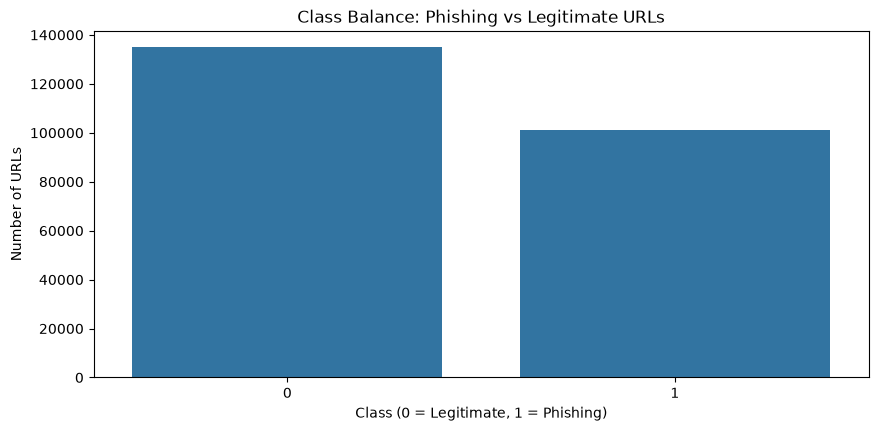

In [14]:
sns.countplot(data=df, x='IsPhishing')

plt.title('Class Balance: Phishing vs Legitimate URLs')
plt.xlabel('Class (0 = Legitimate, 1 = Phishing)')
plt.ylabel('Number of URLs')
plt.show()

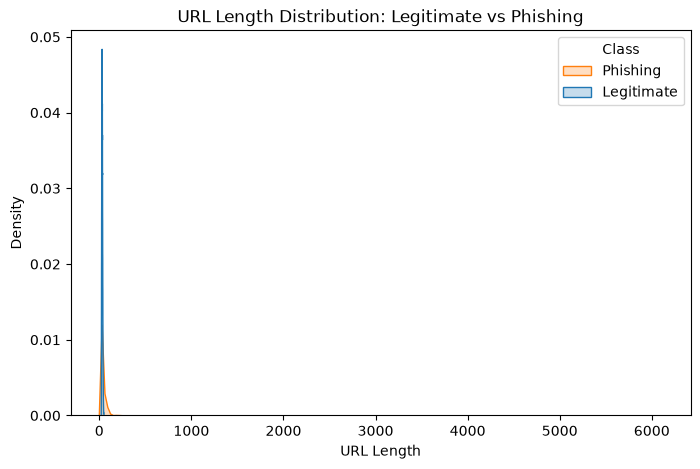

In [15]:
plt.figure(figsize=(8, 5))

sns.kdeplot(data=df, x='URLLength', hue='IsPhishing', fill=True)

plt.title('URL Length Distribution: Legitimate vs Phishing')
plt.xlabel('URL Length')
plt.ylabel('Density')
plt.legend(title='Class', labels=['Phishing', 'Legitimate'])
plt.show()

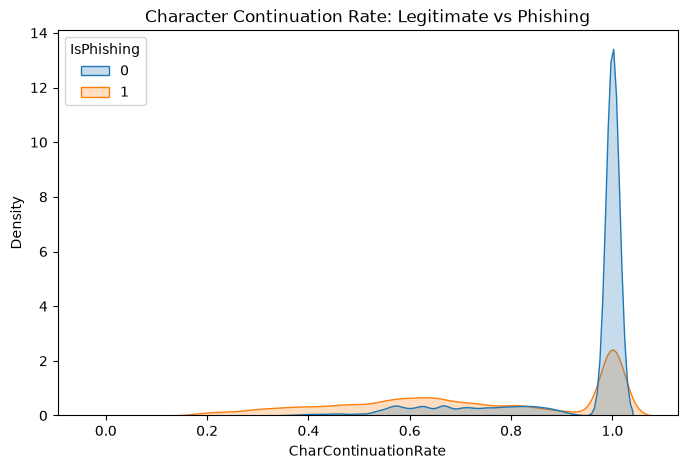

In [16]:
plt.figure(figsize=(8, 5))

sns.kdeplot(data=df, x='CharContinuationRate', hue='IsPhishing', fill=True)

plt.title('Character Continuation Rate: Legitimate vs Phishing')
plt.xlabel('CharContinuationRate')
plt.ylabel('Density')
plt.show()

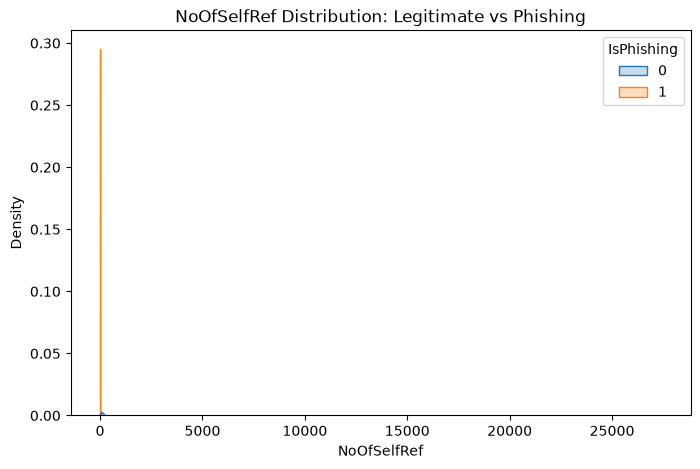

In [19]:
plt.figure(figsize=(8, 5))

sns.kdeplot(data=df, x='NoOfSelfRef', hue='IsPhishing', fill=True)

plt.title('NoOfSelfRef Distribution: Legitimate vs Phishing')
plt.xlabel('NoOfSelfRef')
plt.ylabel('Density')
plt.show()

In [20]:
binary_cols = ['IsHTTPS', 'HasPasswordField', 'HasCopyrightInfo', 'HasSocialNet']

binary_stats = df.groupby('IsPhishing')[binary_cols].mean() * 100

print("Percentage of URLs presenting each indicator:")
display(binary_stats.round(2))

Percentage of URLs presenting each indicator:


,IsHTTPS,HasPasswordField,HasCopyrightInfo,HasSocialNet
IsPhishing,,,,
0,100.00,13.85,80.82,79.46
1,49.22,5.39,5.73,0.51


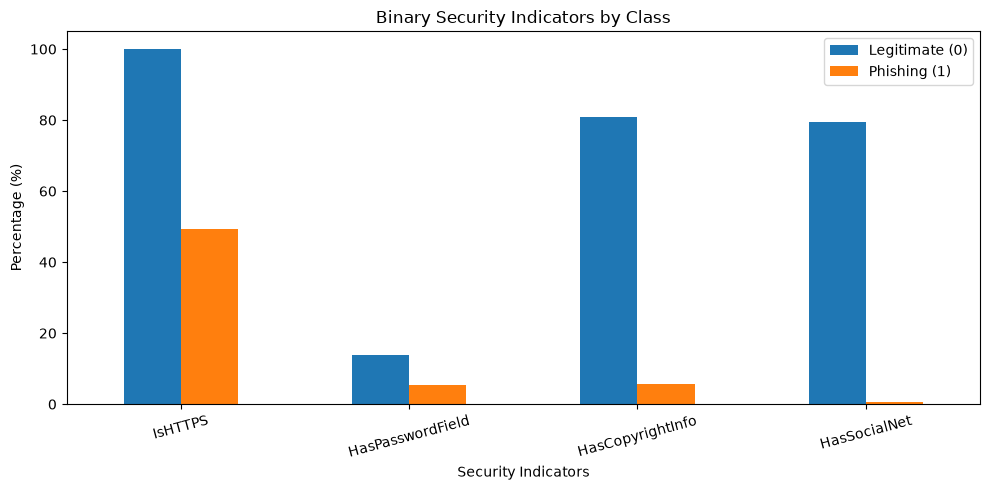

In [21]:
binary_stats.T.plot(kind='bar', figsize=(10, 5))

plt.title('Binary Security Indicators by Class')
plt.xlabel('Security Indicators')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=15)
plt.legend(['Legitimate (0)', 'Phishing (1)'])
plt.tight_layout()
plt.show()

**3 Identifier Cleanup &** **Feature–Target Correlations (Exercise 3)**

We drop non-generalizable raw text strings (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`), the old `label`, and the pre-computed `URLSimilarityIndex` score so our model learns from genuine lexical and HTML indicators. Then we compute the Pearson correlation of each numerical feature with `IsPhishing`.



**3.1 Exercise 3**

In [22]:
columns_to_drop = [
    'FILENAME',
    'URL',
    'Domain',
    'TLD',
    'Title',
    'label',
    'URLSimilarityIndex'
]

X = df.drop(columns=columns_to_drop + ['IsPhishing'], errors='ignore')
y = df['IsPhishing']

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Remaining columns:")
print(X.columns.tolist())

Feature matrix shape: (235795, 49)
Target vector shape: (235795,)
Remaining columns:
['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [23]:
correlations = X.select_dtypes(include='number').corrwith(y)

# Sort correlations
correlations = correlations.sort_values(ascending=False)

# Display the 15 most positively and negatively correlated features
top_positive = correlations.head(15)
top_negative = correlations.tail(15)

print("Top 15 Positively Correlated Features:")
display(top_positive)

print("Top 15 Negatively Correlated Features:")
display(top_negative)

Top 15 Positively Correlated Features:


SpacialCharRatioInURL         0.533537
DegitRatioInURL               0.432032
LetterRatioInURL              0.367794
NoOfOtherSpecialCharsInURL    0.358891
DomainLength                  0.283152
NoOfLettersInURL              0.258090
URLLength                     0.233445
NoOfDegitsInURL               0.177980
NoOfQMarkInURL                0.175621
TLDLength                     0.079159
NoOfEqualsInURL               0.076963
NoOfSelfRedirect              0.076463
IsDomainIP                    0.060202
HasObfuscation                0.052473
NoOfURLRedirect               0.046456
dtype: float64

Top 15 Negatively Correlated Features:


NoOfJS                  -0.373500
Robots                  -0.392620
HasTitle                -0.459725
CharContinuationRate    -0.467735
URLCharProb             -0.469749
HasFavicon              -0.493711
HasHiddenFields         -0.507731
URLTitleMatchScore      -0.539419
IsResponsive            -0.548608
HasSubmitButton         -0.578561
DomainTitleMatchScore   -0.584905
IsHTTPS                 -0.609132
HasDescription          -0.690232
HasCopyrightInfo        -0.743358
HasSocialNet            -0.784255
dtype: float64

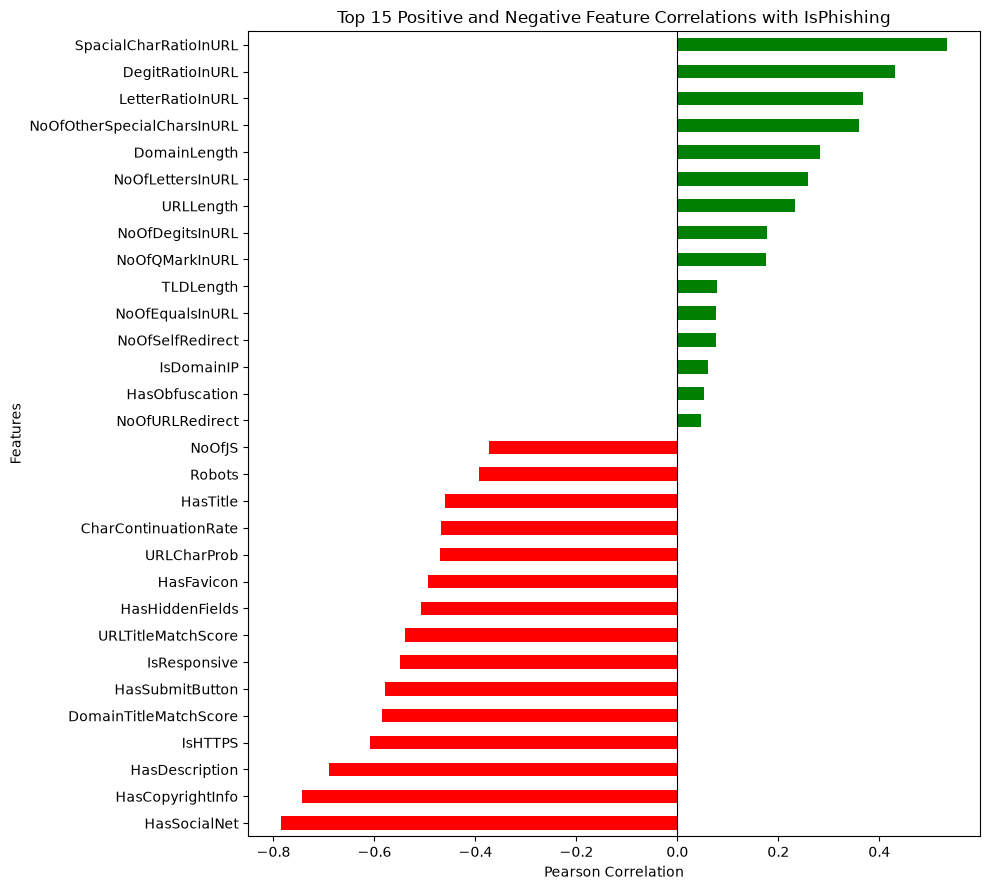

In [24]:
# Combine the 15 highest and 15 lowest correlations
top_features = pd.concat([top_positive, top_negative])

# Creating the horizontal bar plot
plt.figure(figsize=(10, 9))

top_features.sort_values().plot(
    kind='barh',
    color=['red' if value < 0 else 'green'
           for value in top_features.sort_values()]
)

plt.title('Top 15 Positive and Negative Feature Correlations with IsPhishing')
plt.xlabel('Pearson Correlation')
plt.ylabel('Features')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

**Part 1 Reflection Questions**

1. **Looking at your plot for `IsHTTPS`, what percentage of phishing sites currently use an HTTPS certificate? Why is a static rule *"If HTTPS then Legitimate"* dangerous?**
   * **Answer:** Approximately 49.22% of phishing websites in the dataset use HTTPS. A static rule such as "If HTTPS then Legitimate" is dangerous because HTTPS only encrypts communication between the browser and the website; it does not guarantee that the website is trustworthy. Phishing websites can also use HTTPS certificates to appear secure and deceive users.

2. **Why do phishing websites typically have very few internal links (`NoOfSelfRef`) but very frequently contain a password field (`HasPasswordField`)?**
   * **Answer:** Phishing websites are often designed to perform a specific task, such as stealing users' login credentials. They usually have simple structures with few internal links because they do not need extensive navigation. Password fields can be included to collect sensitive information, such as usernames and passwords.

3. **What would happen in production if we left the `FILENAME`, `URL`, or `Domain` column in our training matrix?**
   * **Answer:** The model could memorize specific `filenames`, `URLs`, or `domain` names instead of learning general patterns associated with phishing websites. This could cause overfitting and reduce its ability to detect new, previously unseen phishing URLs. Removing these identifiers helps the model generalize better to real-world data.

**Part 2:** **Zero-Data Leakage Preprocessing & Standardization**

### 4 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)

We apply the **SecMLOps Golden Rule**: split the dataset into training (75%) and test (25%) subsets *before* computing Z-score normalization parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$).



**4.1 Exercise 4**

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (176846, 49)
Testing features: (58949, 49)
Training target: (176846,)
Testing target: (58949,)


In [27]:
# Create the scaler
scaler = StandardScaler()

# Fit ONLY on training data and transform it
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Transform test data using the training scaler
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (176846, 49)
Scaled testing data: (58949, 49)


In [28]:
display(X_train_scaled.head())

,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
107394,-0.247090,-0.488002,-0.052495,0.713116,1.043270,0.858300,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,1.795858,-0.154846,1.028673,0.325555,0.053574,0.143984,-0.086181,-0.127955,0.209325
93048,-0.200666,-0.268943,-0.052495,0.713116,-0.717013,1.192321,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,-0.556837,-0.154846,1.028673,0.124021,0.308934,1.467865,0.241429,-0.127955,0.438964
101580,-0.038183,0.497766,-0.052495,0.713116,-0.717013,1.118549,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,1.795858,-0.154846,1.028673,-0.077514,-0.039284,0.028864,0.304837,-0.127955,-0.179294
230409,-0.293514,-0.707062,-0.052495,0.713116,-1.033217,0.217225,-1.272753,-0.272828,-0.045602,-0.01369,...,-0.382176,1.795858,-0.154846,1.028673,0.552281,-0.027677,-0.086256,0.415802,-0.074340,0.621497
117063,-0.223878,-0.378472,-0.052495,0.713116,1.043270,1.005916,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,-0.556837,-0.154846,1.028673,0.451514,-0.062499,0.431784,0.262565,0.247347,0.480181


In [29]:
print("Training means (first 5 features):")
display(X_train_scaled.mean().head().round(4))

print("\nTraining standard deviations (first 5 features):")
display(X_train_scaled.std().head().round(4))

print("\nTest data shape:", X_test_scaled.shape)

Training means (first 5 features):


URLLength              -0.0
DomainLength           -0.0
IsDomainIP              0.0
CharContinuationRate    0.0
TLDLegitimateProb      -0.0
dtype: float64


Training standard deviations (first 5 features):


URLLength               1.0
DomainLength            1.0
IsDomainIP              1.0
CharContinuationRate    1.0
TLDLegitimateProb       1.0
dtype: float64


Test data shape: (58949, 49)


 **Part 2** **Reflection Questions**

1. **Compare the scale of `LineOfCode` (values up to 10,000+) and `IsHTTPS` (0 or 1) before standardization. Why would L1/L2 regularization be skewed without `StandardScaler`?**
   * **Answer:** `LineOfCode` can have values up to thousands, while `IsHTTPS` only has values of 0 and 1. Without standardization, features with larger values could have more influence on the model. L1 and L2 regularization could also affect features differently because of their different scales. `StandardScaler` solves this by putting all features on a similar scale.

2. **Precisely explain why calling `scaler.fit_transform(X)` before `train_test_split` constitutes Preprocessing Data Leakage.**
   * **Answer:** Calling `scaler.fit_transform(X)` before splitting the dataset allows the scaler to calculate the mean and standard deviation using both training and testing data. This means information from the test set influences the preprocessing of the training data. It creates data leakage because the model indirectly receives information from data that should remain unseen during training. To prevent this, we must fit the scaler only on the training set and use the same scaler to transform the test set.

**Part 3:** **Parameterized Logistic Regression & Interpretability**

### 5 Comparing 5 Logistic Regression Configurations (Exercise 5)

We train and evaluate the five specified Logistic Regression configurations on `X_train_scaled` and `X_test_scaled`:
* **M1: Unregularized (`penalty=None`)**
* **M2: Strong L2 Ridge (`penalty='l2', C=0.001`)**
* **M3: Standard L2 Ridge (`penalty='l2', C=1.0`)**
* **M4: Sparse L1 Lasso (`penalty='l1', C=0.01`)**
* **M5: SOC Weighted (`penalty='l2', C=1.0, class_weight='balanced'`)**



**5.1 Exercise 5**


In [30]:
# Define the five Logistic Regression configurations

models = {
    "M1 - Unregularized": LogisticRegression(
        penalty=None,
        solver='lbfgs',
        max_iter=500,
        random_state=42
    ),

    "M2 - Strong L2": LogisticRegression(
        penalty='l2',
        C=0.001,
        solver='lbfgs',
        max_iter=500,
        random_state=42
    ),

    "M3 - Standard L2": LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='lbfgs',
        max_iter=500,
        random_state=42
    ),

    "M4 - Sparse L1": LogisticRegression(
        penalty='l1',
        C=0.01,
        solver='liblinear',
        max_iter=500,
        random_state=42
    ),

    "M5 - SOC Weighted": LogisticRegression(
        penalty='l2',
        C=1.0,
        class_weight='balanced',
        solver='lbfgs',
        max_iter=500,
        random_state=42
    )
}

print("Five Logistic Regression models defined successfully.")

Five Logistic Regression models defined successfully.


In [31]:
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)

print("\nAll five models trained successfully!")

Training M1 - Unregularized...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Training M2 - Strong L2...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Training M3 - Standard L2...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Training M4 - Sparse L1...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Training M5 - SOC Weighted...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



All five models trained successfully!


In [32]:
results = []

for name, model in models.items():

    # Predict using the default threshold (0.50)
    y_pred = model.predict(X_test_scaled)

    # Calculate the confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    # Count weights close to zero
    zeroed_weights = np.sum(np.abs(model.coef_[0]) < 1e-4)

    # Store the results
    results.append({
        'Model': name,
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall (TPR)': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'PR-AUC': average_precision_score(
            y_test, model.predict_proba(X_test_scaled)[:, 1]
        ),
        'False Positives (FP)': fp,
        'False Negatives (FN)': fn,
        'Zeroed Weights': zeroed_weights
    })

# Create the summary DataFrame
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Precision,Recall (TPR),F1-Score,PR-AUC,False Positives (FP),False Negatives (FN),Zeroed Weights
0,M1 - Unregularized,0.9996,0.9990,0.9993,1.0,11,25,0
1,M2 - Strong L2,0.9985,0.9958,0.9971,1.0,39,105,0
2,M3 - Standard L2,0.9996,0.9989,0.9992,1.0,10,28,0
3,M4 - Sparse L1,0.9993,0.9971,0.9982,1.0,18,72,24
4,M5 - SOC Weighted,0.9995,0.9990,0.9992,1.0,13,25,0


**6-** **L1 Regularization Path & Feature Selection (Exercise 6)**

We vary `C` across `[0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]` with `penalty='l1'` (`solver='liblinear'`) and plot the number of retained features ($|w_j| \ge 10^{-4}$) as a function of `C` on a logarithmic scale.



**6.1 Exercise 6**

Training L1 model with C=0.002...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Active features: 18
Training L1 model with C=0.01...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Active features: 25
Training L1 model with C=0.05...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


... (4 outputs left out)

Active features: 48
Training L1 model with C=1.0...


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Active features: 49


C:\Users\PC PRO\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


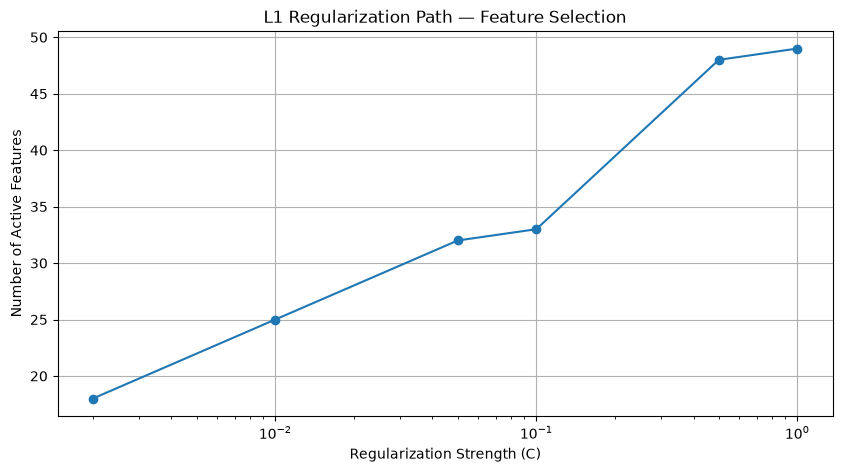

In [ ]:
# Exercise 6 — L1 Regularization Path

# Note: C = 5.0 was excluded because training the model with this value
# took too long and required excessive computational time.
# The experiment was therefore performed using the remaining six C values.

C_values = [0.002, 0.01, 0.05, 0.1, 0.5, 1.0]
active_features_count = []

for c_val in C_values:
    print(f"Training L1 model with C={c_val}...", flush=True)

    m_l1 = LogisticRegression(
        penalty='l1',
        C=c_val,
        solver='liblinear',
        max_iter=500,
        random_state=42
    )

    m_l1_fit = m_l1.fit(X_train_scaled, y_train)

    n_active = np.sum(np.abs(m_l1_fit.coef_[0]) >= 1e-4)
    active_features_count.append(n_active)

    print(f"Active features: {n_active}", flush=True)

# Plot the regularization path
plt.figure(figsize=(10, 5))
plt.plot(C_values, active_features_count, marker='o')
plt.xscale('log')
plt.xlabel('Regularization Strength (C)')
plt.ylabel('Number of Active Features')
plt.title('L1 Regularization Path — Feature Selection')
plt.grid(True)
plt.show()

**7- Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)**

We extract the learned log-odds weights $w_j$ from `M3: Standard L2 Ridge (C=1.0)`, compute the Odds Ratio $e^{w_j}$, compare against `M4: Sparse L1 Lasso (C=0.01)`, and display the **Top 8 Phishing** ($w_j > 0$) and **Top 8 Benign** ($w_j < 0$) features.



**7.1 Exercise 7**

In [34]:
# Extract the trained M3 and M4 models
model_l2 = models['M3 - Standard L2']
model_l1 = models['M4 - Sparse L1']

# Create a DataFrame containing the weights and odds ratios
coef_df = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'L2_Weight': model_l2.coef_[0],
    'Odds_Ratio': np.exp(model_l2.coef_[0]),
    'L1_Sparse_Weight': model_l1.coef_[0]
})

# Top 8 features with positive weights
top_positive = coef_df[coef_df['L2_Weight'] > 0] \
    .sort_values(by='L2_Weight', ascending=False).head(8)

# Top 8 features with negative weights
top_negative = coef_df[coef_df['L2_Weight'] < 0] \
    .sort_values(by='L2_Weight', ascending=True).head(8)

print("Top 8 Positive Features (Increasing Phishing Risk):")
display(top_positive.round(4))

print("Top 8 Negative Features (Indicating Legitimate Sites):")
display(top_negative.round(4))

Top 8 Positive Features (Increasing Phishing Risk):


,Feature,L2_Weight,Odds_Ratio,L1_Sparse_Weight
12,LetterRatioInURL,4.7228,112.4883,2.1726
14,DegitRatioInURL,3.6057,36.8079,1.8036
19,SpacialCharRatioInURL,3.5981,36.5306,1.9106
22,LargestLineLength,2.5575,12.9038,0.0848
18,NoOfOtherSpecialCharsInURL,2.0834,8.0315,0.0000
11,NoOfLettersInURL,1.6801,5.3660,0.0000
3,CharContinuationRate,1.4202,4.1378,0.0000
13,NoOfDegitsInURL,0.9718,2.6426,0.0000


Top 8 Negative Features (Indicating Legitimate Sites):


,Feature,L2_Weight,Odds_Ratio,L1_Sparse_Weight
20,IsHTTPS,-6.9024,0.0010,-3.5777
45,NoOfJS,-3.6536,0.0259,-1.2017
46,NoOfSelfRef,-3.1249,0.0439,-0.8227
43,NoOfImage,-2.7981,0.0609,-0.1505
48,NoOfExternalRef,-2.6414,0.0713,-0.0157
21,LineOfCode,-2.3676,0.0937,0.0000
35,HasSocialNet,-2.1533,0.1161,-1.0887
1,DomainLength,-1.9117,0.1478,-0.0585


 **Part 3** **Reflection Questions —**

1. **How many variables did `M4: Sparse L1 Lasso (C=0.01)` eliminate (weights set to zero)? Did the F1-Score drop significantly? What is the advantage for a real-time firewall?**
   * **Answer:** M4 eliminated 24 out of 49 features by setting their coefficients close to zero. Its F1-score decreased slightly from 0.9993 (M1) to 0.9982, while its PR-AUC remained 1.0000 when rounded to four decimal places. This is not a significant drop in performance. For a real-time firewall, using fewer features can make the model simpler, faster, and easier to maintain while still providing very good phishing detection.

2. **What is the impact of `class_weight='balanced'` (M5) on False Positives and False Negatives compared to M3?**
   * **Answer:** ompared to M3, M5 increased false positives from 10 to 13 and decreased false negatives from 28 to 25. This means the balanced model detected slightly more phishing websites but incorrectly classified a few more legitimate websites as phishing. This can be useful in cybersecurity because missing a phishing website can be more dangerous than blocking a legitimate one.

3. **How do you interpret a positive weight $w_j > 0$ versus a negative weight $w_j < 0$ in the formula $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?**
   * **Answer:** A positive weight (\(w_j > 0\)) means that when the feature increases, the model becomes more likely to classify the URL as phishing. Its Odds Ratio (\(e^{w_j} > 1\)) indicates an increase in phishing odds.

   A negative weight (\(w_j < 0\)) means that when the feature increases, the model becomes less likely to classify the URL as phishing. Its Odds Ratio (\(e^{w_j} < 1\)) indicates a decrease in phishing odds. These weights contribute to the final prediction through the logistic function.

**Part 4:** **Explainable AI (SHAP) & SOC Threshold Analysis**

### 8 Global Explanations with `shap.LinearExplainer` (Exercise 8)

We initialize `shap.LinearExplainer` on `model_l2` (`M3`) using `X_train_scaled` as the background reference distribution, compute exact Shapley values on the first `1,000` test URLs, and plot the global Bar and Beeswarm charts (`max_display=15`).



8.1 Exercise 8

In [35]:
# Initialize SHAP LinearExplainer using the training data
explainer = shap.LinearExplainer(model_l2, X_train_scaled)

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


In [36]:
# Calculate SHAP values for the first 1,000 test URLs
shap_values = explainer(X_test_scaled.iloc[:1000])

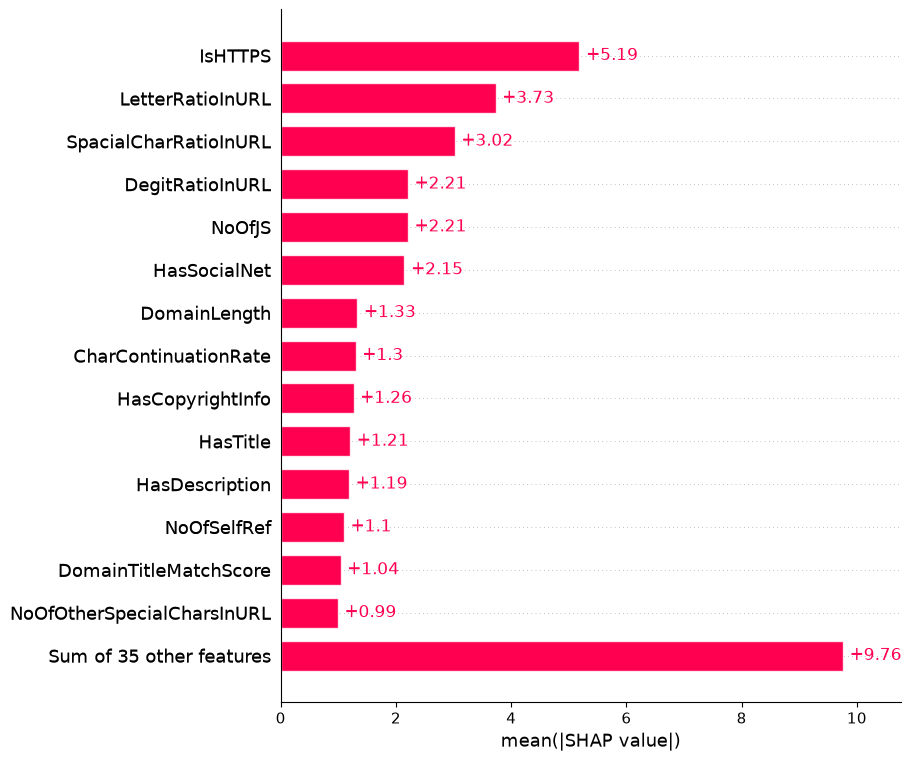

In [37]:
# Global feature importance
shap.plots.bar(shap_values, max_display=15)

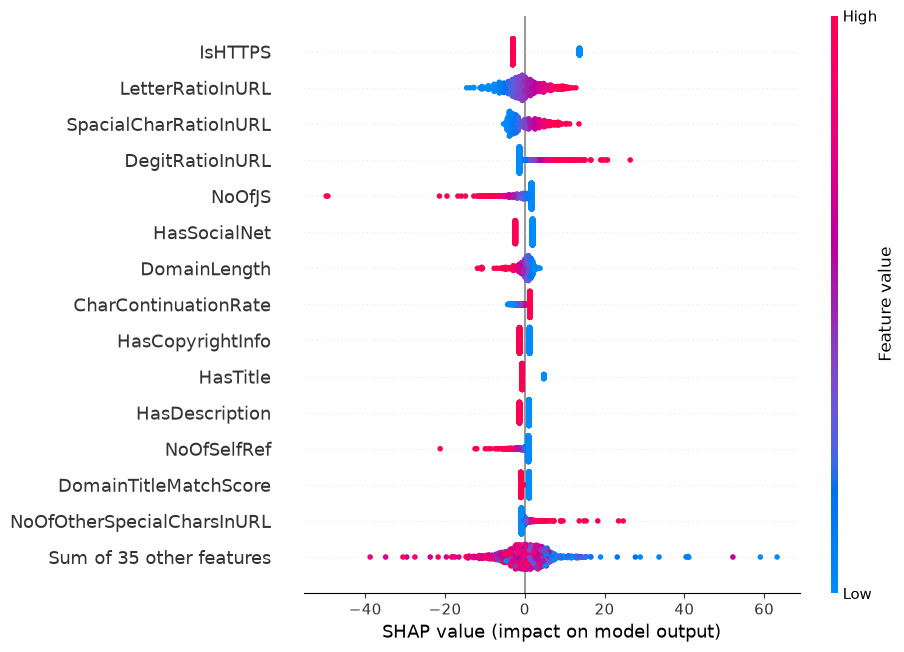

In [38]:
# Global SHAP beeswarm plot
shap.plots.beeswarm(shap_values, max_display=15)

**9-** **Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)**

We locate the first **True Positive (TP)**, **True Negative (TN)**, and **False Positive (FP — False Alarm)** in our 1,000-URL test sample and inspect their local SHAP Waterfall plots (`max_display=10`), passing unscaled `X_test` values in `data=` so SOC analysts can read actual URL metrics.


**9.1** **Exercise 9**

In [39]:
# Predictions for the first 1,000 test URLs
y_pred_sample = model_l2.predict(X_test_scaled.iloc[:1000])
y_true_sample = y_test.iloc[:1000].values

# Count each type of result
tp_indices = np.where((y_true_sample == 1) & (y_pred_sample == 1))[0]
tn_indices = np.where((y_true_sample == 0) & (y_pred_sample == 0))[0]
fp_indices = np.where((y_true_sample == 0) & (y_pred_sample == 1))[0]
fn_indices = np.where((y_true_sample == 1) & (y_pred_sample == 0))[0]

print("True Positives:", len(tp_indices))
print("True Negatives:", len(tn_indices))
print("False Positives:", len(fp_indices))
print("False Negatives:", len(fn_indices))

True Positives: 421
True Negatives: 579
False Positives: 0
False Negatives: 0


In [40]:
# Predict on the entire test set
y_pred_all = model_l2.predict(X_test_scaled)

# Find the indices of TP, TN and FP
tp_indices_all = np.where((y_test.values == 1) & (y_pred_all == 1))[0]
tn_indices_all = np.where((y_test.values == 0) & (y_pred_all == 0))[0]
fp_indices_all = np.where((y_test.values == 0) & (y_pred_all == 1))[0]

print("TP available:", len(tp_indices_all))
print("TN available:", len(tn_indices_all))
print("FP available:", len(fp_indices_all))

TP available: 25208
TN available: 33703
FP available: 10


In [41]:
tp_idx = tp_indices_all[0]
tn_idx = tn_indices_all[0]
fp_idx = fp_indices_all[0]

print("TP index:", tp_idx)
print("TN index:", tn_idx)
print("FP index:", fp_idx)

TP index: 2
TN index: 0
FP index: 3590


1. True Positive (TP)

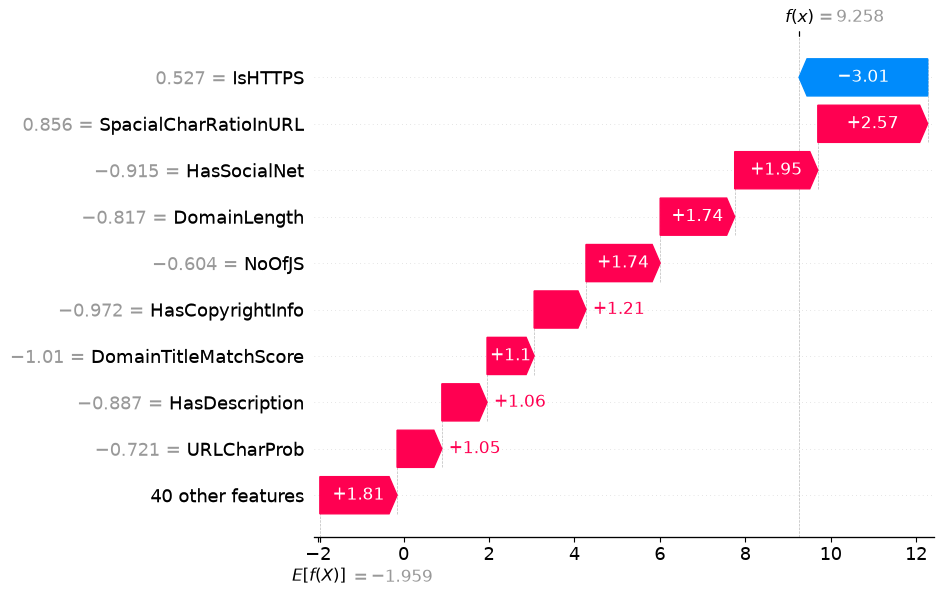

In [42]:
shap.plots.waterfall(
    explainer(X_test_scaled.iloc[[tp_idx]])[0],
    max_display=10
)

2. True Negative (TN)

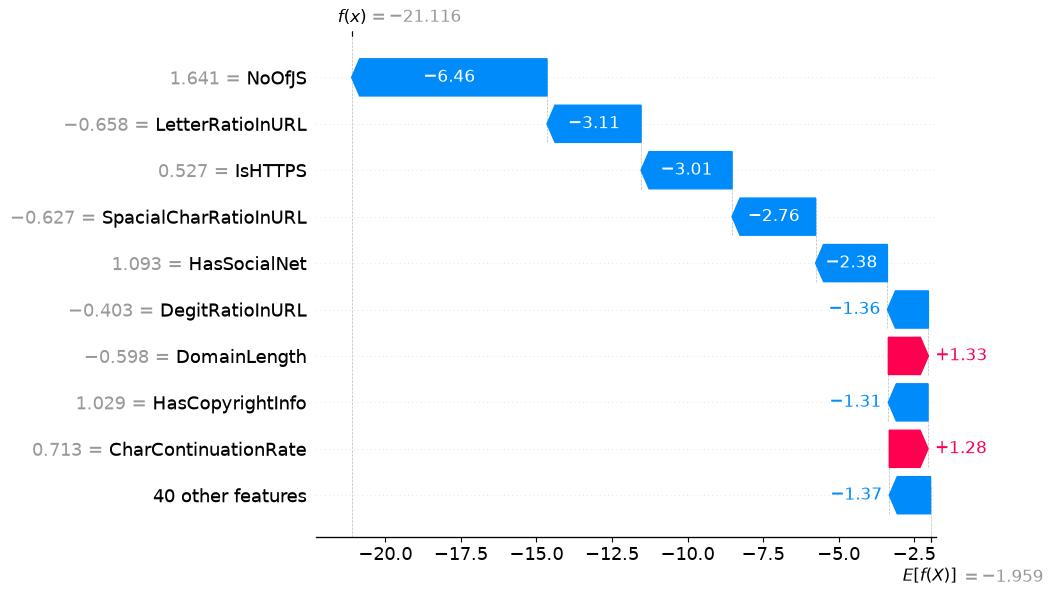

In [43]:
shap.plots.waterfall(
    explainer(X_test_scaled.iloc[[tn_idx]])[0],
    max_display=10
)

3. False Positive (FP)

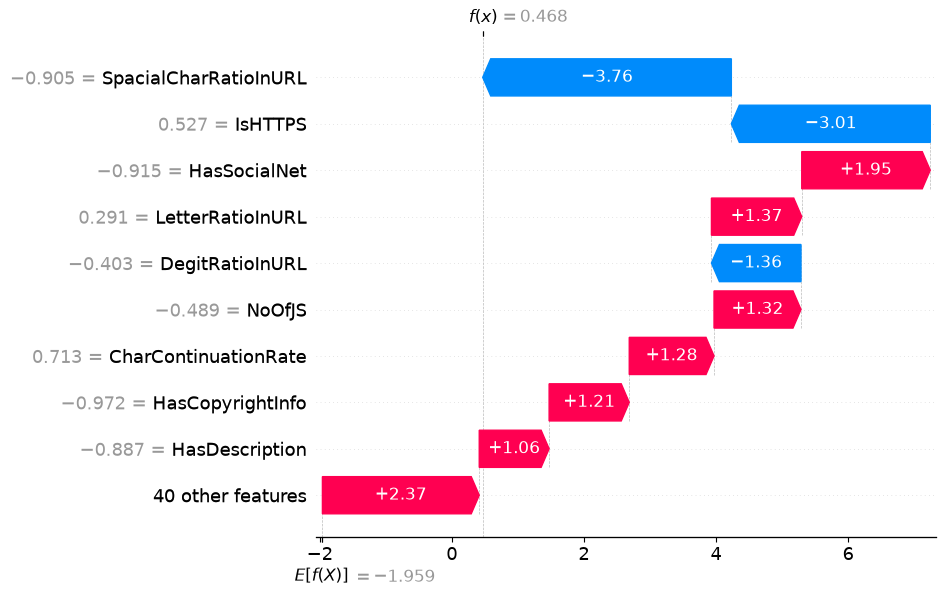

In [44]:
shap.plots.waterfall(
    explainer(X_test_scaled.iloc[[fp_idx]])[0],
    max_display=10
)

**10. Exercise 10** — **Operational Decision Threshold Tuning ($\tau$):**


We evaluate `model_l2` (`M3`) on the full test set across three operational decision thresholds:
* **$\tau = 0.20$ (Threat Hunting Mode):** Maximizes Recall to catch stealthy phishing campaigns.
* **$\tau = 0.50$ (Default Mode):** Balanced threshold.
* **$\tau = 0.85$ (Automated Firewall Blocking Mode):** Maximizes Precision and minimizes False Positives to prevent blocking legitimate business traffic.

In [45]:
# Get phishing probabilities from M3 for the full test set
y_proba = model_l2.predict_proba(X_test_scaled)[:, 1]

print("Number of test URLs:", len(y_proba))
print("First 10 phishing probabilities:")
print(y_proba[:10])

Number of test URLs: 58949
First 10 phishing probabilities:
[6.75282171e-10 2.14748896e-11 9.99904703e-01 4.70697000e-06
 4.57932463e-11 1.00000000e+00 9.91476070e-05 1.83886733e-05
 1.00000000e+00 3.93491164e-16]


In [46]:
thresholds = [0.20, 0.50, 0.85]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    y_pred_threshold = (y_proba >= threshold).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold, zero_division=0)
    f1 = f1_score(y_test, y_pred_threshold, zero_division=0)

    threshold_results.append({
        'Threshold': threshold,
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,TP,TN,FP,FN,Precision,Recall,F1-Score
0,0.20,25221,33682,31,15,0.9988,0.9994,0.9991
1,0.50,25208,33703,10,28,0.9996,0.9989,0.9992
2,0.85,25172,33713,0,64,1.0000,0.9975,0.9987


 **Part 4** **Reflection Questions** —

1. **What is the mathematical difference between inspecting a global weight $w_j$ and looking at a local SHAP value $\phi_j(x)$ for a specific URL?**
   * **Answer:** A global weight `(\(w_j\))` represents the overall influence of a feature on the model's prediction. It is the same for all URLs in the Logistic Regression model. A local SHAP value `$\phi_j(x)$` explains how much a specific feature contributes to the prediction of one particular URL. Therefore, the weight describes the model's learned relationship, while the SHAP value explains the feature's contribution to an individual prediction.

2. **On your False Positive (FP) Waterfall plot, which 2 or 3 features misled the model and caused this false alarm?**
   * **Answer:** The three main features that misled the model were `HasSocialNet`, `LetterRatioInURL`, and `NoOfJS`. Their positive SHAP values pushed the prediction toward phishing, even though the URL was actually legitimate. These features contributed to the false alarm by making the website appear more suspicious to the model.

3. **Why would a SOC deploy $\tau = 0.85$ for automated DNS/firewall blocking while routing URLs with $0.20 \le P(\text{Phishing}) < 0.85$ to a human analyst queue?**
   * **Answer:** A threshold of 0.85 reduces false positives and prevents blocking legitimate websites. Less certain URLs (0.20–0.85) are sent to human analysts for review instead of being automatically blocked. This combines automated protection with human judgment.

**6 - Conclusion &** **SOC Engineering Synthesis (Deliverable Solution)**

> ### 🛡️ SOC Engineering Synthesis Report
> 1. **Hyperparameter & Sparsity Trade-Off:** M3 (L2, C=1.0) achieved the best performance with an F1-score of 0.9992 and 10 false positives. M4 (L1) eliminated 24 of 49 features while maintaining an F1-score of 0.9982.

> 2. **Global Interpretability (Odds Ratios & SHAP):** The main phishing indicators were `LetterRatioInURL`, `DegitRatioInURL`, and `SpacialCharRatioInURL`. `IsHTTPS`, `NoOfJS`, and `NoOfSelfRef` were associated with legitimate websites. `SHAP` confirmed that `IsHTTPS`, `LetterRatioInURL`, and `SpacialCharRatioInURL` were the most influential features.

> 3. **SOC Alert Triage & Dual-Threshold Policy:**
 * *False Positive Triage Note (3 sentences):* `HasSocialNet`, `LetterRatioInURL`, and `NoOfJS` pushed a legitimate URL toward a phishing prediction. This false alarm shows the importance of human review.

  * *Recommended Threshold Policy:*

   **Threshold 0.20 –** Threat Hunting: Prioritizes detecting phishing websites, achieving 0.9994 recall, but generates 31 false positives.

   **Threshold 0.50 –** Balanced Detection: Provides a balance between precision (0.9996) and recall (0.9989), with 10 false positives and 28 false negatives.

   **Threshold 0.85 –** Automated Blocking: Produces zero false positives in the test set, but misses 64 phishing URLs.

   **Human Review:** URLs with probabilities between 0.20 and 0.85 should be sent to SOC analysts for manual investigation before taking action.